In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
num_notes = 50
sequence_length = 30
num_sequences = 1000

data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))

# Q1a: Separate input and target
x_train = data[:, :-1]
y_train = data[:, 1:]

# Q1b: One-hot encoding
NUM_CLASSES = num_notes

x_train = to_categorical(x_train, num_classes=NUM_CLASSES)
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)

print("x_train:", x_train.shape, " y_train:", y_train.shape)

x_train: (1000, 29, 50)  y_train: (1000, 29, 50)


In [3]:
assert x_train.shape == (1000, 29, 50)
assert y_train.shape == (1000, 29, 50)

print("Task 1 looks correct ✔")

Task 1 looks correct ✔


In [4]:
model = models.Sequential()

model.add(layers.Input(shape=(sequence_length-1, num_notes)))

# Q2a: First Bidirectional LSTM
model.add(layers.Bidirectional(
    layers.LSTM(128, return_sequences=True)
))

# Q2b: Second Bidirectional LSTM
model.add(layers.Bidirectional(
    layers.LSTM(128, return_sequences=True)
))

# Q2c: TimeDistributed Dense output
model.add(layers.TimeDistributed(
    layers.Dense(50, activation='softmax')
))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 29, 256)        │       183,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 29, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 29, 50)         │        12,850 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,386 (2.25 MB)

 Trainable params: 590,386 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Q3a: Compile the model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Q3b: Train the model
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 402ms/step - accuracy: 0.0998 - loss: 3.8848 - val_accuracy: 0.1752 - val_loss: 3.8440
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 435ms/step - accuracy: 0.1457 - loss: 3.7730 - val_accuracy: 0.1179 - val_loss: 3.6447
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 305ms/step - accuracy: 0.1199 - loss: 3.5109 - val_accuracy: 0.1434 - val_loss: 3.4092
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 303ms/step - accuracy: 0.1591 - loss: 3.2361 - val_accuracy: 0.1812 - val_loss: 3.1050
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 531ms/step - accuracy: 0.2083 - loss: 2.8921 - val_accuracy: 0.2378 - val_loss: 2.7258
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 306ms/step - accuracy: 0.2694 - loss: 2.4966 - val_accuracy: 0.3060 - val_loss: 2.3387
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 506ms/step - accuracy: 0.3509 - loss: 2.1037 - val_accuracy: 0.3890 - val_loss: 1.9597
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 413ms/step - accuracy: 0.4353 - loss: 1.7329 - val_accuracy: 0

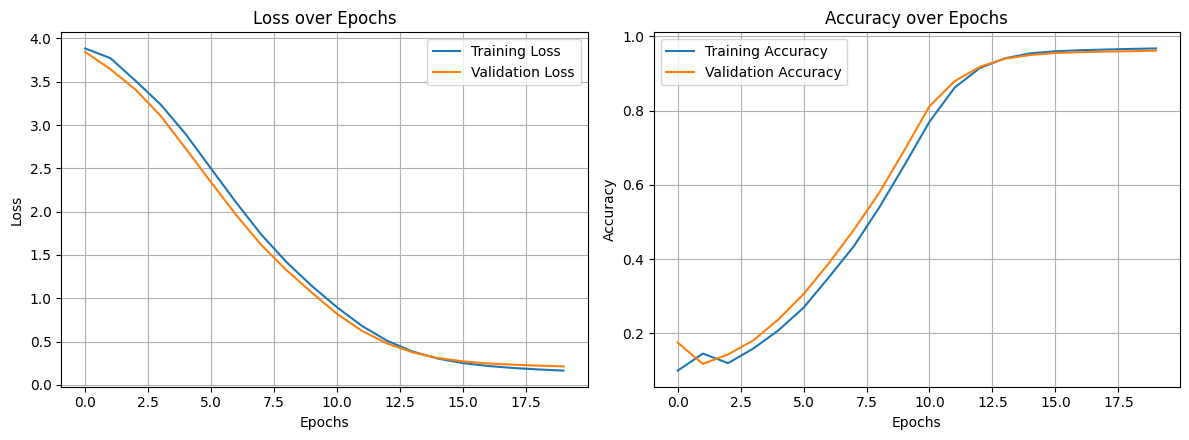

In [6]:
plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [7]:
def generate_music(model, start_sequence, num_generated_notes=50):

    generated = []
    current_sequence = start_sequence

    for _ in range(num_generated_notes):

        pred = model.predict(current_sequence, verbose=0)

        # Q5a: Predict the most likely next note
        next_note = np.argmax(pred[:, -1, :], axis=-1)

        generated.append(int(next_note[0]))

        # Q5b: Slide the window
        oh = to_categorical(next_note, num_classes=num_notes).reshape(1, 1, num_notes)

        current_sequence = np.concatenate(
            [current_sequence[:, 1:, :], oh],
            axis=1
        )

    return generated


# Seed window
start = np.random.randint(0, num_notes, size=(1, sequence_length-1))
start = to_categorical(start, num_classes=num_notes)

# Generate 50 notes
generated_music = generate_music(model, start, num_generated_notes=50)

print("Generated:", generated_music)

Generated: [28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28]


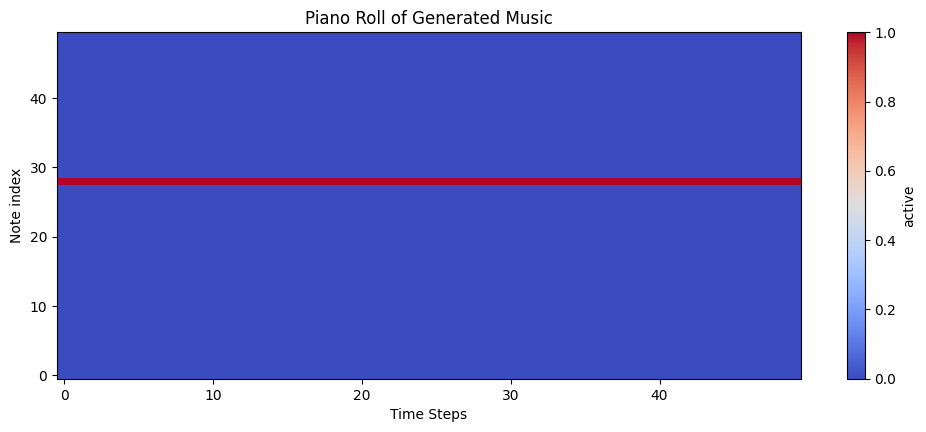

In [8]:
piano_roll = np.zeros((num_notes, len(generated_music)))

for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1

plt.figure(figsize=(12, 4.5))

plt.imshow(
    piano_roll,
    aspect='auto',
    cmap='coolwarm',
    origin='lower',
    interpolation='nearest'
)

plt.colorbar(label='active')
plt.title('Piano Roll of Generated Music')
plt.xlabel('Time Steps')
plt.ylabel('Note index')
plt.show()

1. What would break if you set return_sequences=False on the first layer?

The first Bi-LSTM would return only the final output instead of an output at every time step. The second Bi-LSTM requires a sequence as input. Therefore, the model would not work as intended.

2. Why is the first Bi-LSTM's output width 256 when the LSTM has 128 units?

A Bidirectional LSTM processes the input in two directions: forward and backward. Each direction has 128 units. Therefore, the output width is 128 + 128 = 256.

3. What does TimeDistributed(Dense(50)) do that a plain Dense(50) would not?

TimeDistributed applies the same Dense layer independently to every time step of the input sequence. It produces a prediction of 50 possible notes at every time step.

4. You trained on random notes, yet accuracy reaches approximately 96%. Explain the mechanism.

The high accuracy happens because of information leakage. The target at time step t is the input at time step t+1. Since the Bidirectional LSTM processes the sequence in both forward and backward directions, the backward layer can access future information and indirectly see the correct target. Therefore, the model achieves high accuracy without actually learning meaningful music patterns.

5. Why is a bidirectional model a poor choice for autoregressive generation, and what two changes would make this an honest music generator?

A Bidirectional LSTM uses both past and future information. During music generation, future notes are not available because the model must predict them one at a time.

Two changes would make it an honest music generator:
1. Replace Bidirectional LSTM layers with normal unidirectional LSTM layers so that the model uses only previous notes.
2. Train the model using real musical sequences instead of randomly generated notes.

import pypandoc

content = r"""# Bi-LSTM Parameter Calculation

## First Bidirectional LSTM

The parameter-count formula for an LSTM layer is:

\[
4 \times [(n_{\text{input}} + n_{\text{units}}) \times n_{\text{units}} + n_{\text{units}}]
\]

A Bidirectional LSTM has two directions, so we multiply by 2.

For the first Bi-LSTM:

- Input features = 50
- LSTM units = 128
- Number of directions = 2

\[
\text{Parameters} = 2 \times 4 \times [(50 + 128) \times 128 + 128]
\]

\[
= 2 \times 4 \times [(178 \times 128) + 128]
\]

\[
= 2 \times 4 \times [22784 + 128]
\]

\[
= 2 \times 4 \times 22912
\]

\[
\boxed{183296}
\]

**The first Bi-LSTM has 183,296 parameters.**

## Second Bidirectional LSTM

The second Bi-LSTM receives the output of the first Bi-LSTM.

Since the first Bi-LSTM has 128 units in each direction, its output width is:

\[
128 + 128 = 256
\]

Therefore:

- Input features = 256
- LSTM units = 128
- Number of directions = 2

\[
\text{Parameters} = 2 \times 4 \times [(256 + 128) \times 128 + 128]
\]

\[
= 2 \times 4 \times [(384 \times 128) + 128]
\]

\[
= 2 \times 4 \times [49152 + 128]
\]

\[
= 2 \times 4 \times 49280
\]

\[
\boxed{394240}
\]

**The second Bi-LSTM has 394,240 parameters.**

## Explanation

The second Bi-LSTM has more parameters because its input contains 256 features from the previous Bidirectional LSTM instead of 50 features. A larger input width requires more input weights, increasing the total number of parameters.

## Final Results

| Layer | Number of parameters |
|---|---:|
| First Bidirectional LSTM | 183,296 |
| Second Bidirectional LSTM | 394,240 |
"""

output_path = "/mnt/data/BiLSTM_Parameter_Calculation.md"
pypandoc.convert_text(
    content,
    "md",
    format="md",
    outputfile=output_path,
    extra_args=["--standalone"]
)

print(f"Created: {output_path}")
